# QLBM D1Q2 : advection-diffusion et circuits de spin

Ce notebook construit et teste un modèle minimal de transport sur un réseau, puis étudie ce qu’il devient lorsqu’on l’encode dans un circuit quantique et qu’on le compile avec SpinPulse.

## Le modèle physique

On cherche à reproduire l’évolution d’une densité \(u(x,t)\) selon l’équation d’advection-diffusion :

$$\partial_t u + a\,\partial_x u = D\,\partial_x^2 u.$$

La méthode Lattice Boltzmann remplace directement cette équation par deux populations fictives $f_+(x,t)$ et $f_-(x,t)$. Elles se déplacent à une vitesse discrète \(+1\) ou \(-1\), puis sont mélangées localement. La densité est $u=f_++f_-$ ; leur différence représente le flux.

Une itération comporte donc deux opérations :

1. **Collision locale** : les populations se rapprochent d’un équilibre qui porte la vitesse moyenne $a$. Le paramètre $\omega=1/\tau$ règle la vitesse de relaxation et, par conséquent, la diffusivité.
2. **Transport** : chaque population se déplace d’un site dans le sens de sa vitesse. Aux deux extrémités du réseau, le code inverse la direction : ce sont des parois réfléchissantes (*bounce-back*).

Le modèle est volontairement linéaire et très simple (une dimension, deux vitesses) : il illustre le mécanisme LBM, mais ne constitue pas une simulation complète de la météo ou d’un fluide réaliste.

## Encodage quantique et conventions

Pour \(N=2^n\) sites, le registre contient \(n\) qubits de position, un qubit de vitesse \(v\), et un qubit auxiliaire (*ancilla*) utilisé pour la collision : au total \(n+2\) qubits. La convention little-endian de Qiskit est utilisée : les qubits de position sont les indices `0..n-1`, puis `v = n` et `ancilla = n+1`.

Les populations sont encodées dans les **amplitudes** d’un état normalisé en norme \(\ell_2\), et non dans les probabilités de mesure ni dans la masse physique \(\sum_x u(x)\). La collision, qui n’est pas unitaire, est réalisée par une dilatation unitaire puis une post-sélection sur `ancilla = 0`. Cette étape est probabiliste ; le notebook suit sa probabilité de succès et rétablit l’échelle des populations.

Le fil du notebook va de la référence NumPy à la simulation quantique idéale, puis à la compilation et à la simulation bruitée SpinPulse. La solution gaussienne analytique sert de repère sur un domaine infini ; elle ne possède pas les mêmes conditions aux limites que le réseau réfléchissant.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister
from qiskit.quantum_info import Statevector

# Paramètres de l’équation d’advection-diffusion (unités réseau).
A_ADV = 0.4  # vitesse moyenne d’advection a, en sites par pas
D_EFF = 0.10  # diffusivité effective visée, en sites² par pas
N_STEPS = 4  # nombre de pas de temps simulés


def omega_from_D(D, a):
    """Convertit D en fréquence de relaxation omega pour le modèle D1Q2."""
    tau = 0.5 + D / (1.0 - a * a)
    return 1.0 / tau


def D_from_omega(omega, a):
    """Calcule la diffusivité associée à omega et à la vitesse moyenne a."""
    tau = 1.0 / omega
    return (tau - 0.5) * (1.0 - a * a)


## 1. Référence classique : les deux étapes de la LBM

Cette partie définit une référence NumPy indépendante du matériel quantique. Elle fournit les mêmes populations, le même ordre d’opérations et les mêmes parois réfléchissantes que le circuit que l’on construira ensuite.

### Équilibre et collision

Les deux vitesses discrètes valent \(c_+=+1\) et \(c_-=-1\). Pour une densité \(u=f_++f_-\), l’équilibre choisi est

$$f_+^{\mathrm{eq}}=\frac{1+a}{2}u,\qquad f_-^{\mathrm{eq}}=\frac{1-a}{2}u.$$

La somme de ces deux populations vaut \(u\), et leur flux \(f_+^{\mathrm{eq}}-f_-^{\mathrm{eq}}\) vaut \(a u\) : le paramètre `a` impose donc la vitesse moyenne de l’advection. La collision BGK rapproche chaque population de cet équilibre :

$$f^* = (1-\omega)f + \omega f^{\mathrm{eq}}.$$

Elle conserve la densité locale. Pour ce modèle D1Q2, la diffusivité associée est

$$D=(\tau-\tfrac12)(1-a^2),\qquad \tau=\frac1\omega.$$

### Transport et conditions aux limites

Après la collision, `f_+` va vers le site suivant et `f_-` vers le site précédent. Aux bords, la population entrante est remplacée par celle qui rebondit : aucune population ne quitte le domaine.

`initial_density` prépare une bosse gaussienne discrète. `analytic_gaussian` donne la solution de l’équation continue sur un domaine infini ; elle est utile pour comparer la propagation et l’élargissement, mais les réflexions aux bords peuvent faire diverger cette courbe de la référence LBM.

In [2]:
def collision_matrix(a, omega):
    """Retourne la matrice de collision BGK pour les deux vitesses D1Q2."""
    equilibrium = 0.5 * np.array(
        [[1 + a, 1 + a], [1 - a, 1 - a]]
    )
    return (1 - omega) * np.eye(2) + omega * equilibrium


def stream_reflect(f):
    """Déplace les populations et les réfléchit aux deux extrémités.

    `f[0]` correspond à la vitesse +1 et `f[1]` à la vitesse -1.
    """
    n_sites = f.shape[1]
    streamed = np.zeros_like(f)

    # Les populations qui ne rencontrent pas de bord avancent dans leur sens.
    streamed[0, 1:] = f[0, :-1]
    streamed[1, :-1] = f[1, 1:]

    # Aux bords, on inverse la direction au lieu de quitter le domaine.
    streamed[1, n_sites - 1] = f[0, n_sites - 1]
    streamed[0, 0] = f[1, 0]
    return streamed


def lbm_step_numpy(f, a, omega):
    """Applique la collision locale, puis le transport avec rebond."""
    collided = collision_matrix(a, omega) @ f
    return stream_reflect(collided)


def initial_density(N, x0=None, sigma=None):
    """Crée une bosse gaussienne discrète et renvoie aussi son centre et sa largeur."""
    x = np.arange(N)
    x0 = N / 2 - 1.5 if x0 is None else x0
    sigma = N / 8 if sigma is None else sigma
    density = np.exp(-((x - x0) ** 2) / (2 * sigma**2))
    return density, x0, sigma


def f_equilibrium(u, a):
    """Répartit la densité selon les populations d'équilibre de vitesse moyenne a."""
    f_plus = 0.5 * (1 + a) * u
    f_minus = 0.5 * (1 - a) * u
    return np.array([f_plus, f_minus])


def run_numpy(N, a, omega, K):
    """Calcule et renvoie les populations du temps 0 jusqu'au temps K inclus."""
    density, _, _ = initial_density(N)
    populations = f_equilibrium(density, a)
    trajectory = [populations.copy()]

    for _ in range(K):
        populations = lbm_step_numpy(populations, a, omega)
        trajectory.append(populations.copy())
    return trajectory


def analytic_gaussian(N, a, D, t, x0, sigma, xs=None):
    """Solution gaussienne continue sur un domaine infini, échantillonnée en xs."""
    xs = np.linspace(-0.5, N - 0.5, 400) if xs is None else xs
    variance = sigma**2 + 2 * D * t
    amplitude = sigma / np.sqrt(variance)
    profile = amplitude * np.exp(-((xs - x0 - a * t) ** 2) / (2 * variance))
    return xs, profile

## 2. Collision non unitaire : la réaliser avec une ancilla

La collision agit localement sur les deux composantes de vitesse, avec la matrice \(C\) définie dans la section précédente. Elle conserve la masse, mais elle peut réduire la norme \(\ell_2\) du vecteur des populations : elle n’est donc pas, en général, une opération unitaire directement réalisable sur un registre quantique.

La fonction `dilation` transforme \(C\) en un bloc d’une matrice unitaire \(U\). Elle normalise d’abord \(C\) par sa norme spectrale \(\alpha\), puis complète \(T=C/\alpha\) avec les racines carrées de \(I-TT^\dagger\) et \(I-T^\dagger T\). La décomposition en valeurs singulières permet de calculer ces racines de façon stable, y compris lorsqu’une valeur singulière vaut 1.

Quand l’ancilla commence à 0, le bloc correspondant à `ancilla = 0` applique \(T\). Garder uniquement les résultats où l’ancilla vaut 0 revient donc à appliquer la collision normalisée ; la probabilité de garder un résultat n’est pas forcément 1. Le facteur \(\alpha\), ainsi que la probabilité de post-sélection, sont réutilisés ensuite pour reconstruire l’échelle physique des populations.

In [ ]:
def dilation(C):
    """Construit une dilatation unitaire dont le bloc ancilla=0 encode C/alpha.

    L'ordre des indices de U est `v + 2*ancilla`, comme pour
    `qc.unitary(U, [v, anc])`. Les racines matricielles sont calculées par SVD
    pour éviter les imprécisions lorsque C possède une valeur singulière égale à 1.
    """
    alpha = np.linalg.norm(C, 2)
    T = C / alpha #Normalisation 

    left_vectors, singular_values, right_vectors_h = np.linalg.svd(T)
    complementary_values = np.sqrt(
        np.clip(1.0 - singular_values**2, 0.0, None)
    )

    sqrt_left = (left_vectors * complementary_values) @ left_vectors.conj().T
    right_vectors = right_vectors_h.conj().T
    sqrt_right = (right_vectors * complementary_values) @ right_vectors_h

    unitary = np.block(
        [[T, sqrt_left], [sqrt_right, -T.conj().T]]
    )
    assert np.allclose(unitary @ unitary.conj().T, np.eye(4), atol=1e-12)
    return unitary, alpha

In [4]:
def _qft_noswap(circuit, register, inverse=False):
    """Ajoute une QFT sans SWAP finaux sur un registre little-endian."""
    n_qubits = len(register)
    gates = []

    for target in range(n_qubits - 1, -1, -1):
        gates.append(("h", target, None, None))
        for control in range(target - 1, -1, -1):
            angle = np.pi / 2 ** (target - control)
            gates.append(("cp", control, target, angle))

    if inverse:
        gates.reverse()

    for gate, first, second, angle in gates:
        if gate == "h":
            circuit.h(register[first])
        else:
            circuit.cp(
                -angle if inverse else angle,
                register[first],
                register[second],
            )


def incr_mcx(circuit, register):
    """Ajoute 1 modulo 2**m avec des portes multi-contrôlées Qiskit."""
    for target in range(len(register) - 1, 0, -1):
        circuit.mcx(register[:target], register[target])
    circuit.x(register[0])


def incr_draper(circuit, register):
    """Ajoute 1 modulo 2**m avec QFT, phases, puis QFT inverse."""
    _qft_noswap(circuit, register)
    for bit_index, qubit in enumerate(register):
        circuit.p(np.pi / 2**bit_index, qubit)
    _qft_noswap(circuit, register, inverse=True)


def add_collision(circuit, unitary, velocity_qubit, ancilla_qubit,
                  decompose_cx=False):
    """Ajoute la collision dilatée, directement ou décomposée en portes CX."""
    if decompose_cx:
        from qiskit.circuit.library import CXGate
        from qiskit.synthesis import TwoQubitBasisDecomposer

        decomposition = TwoQubitBasisDecomposer(CXGate())(unitary)
        circuit.compose(
            decomposition,
            qubits=[velocity_qubit, ancilla_qubit],
            inplace=True,
        )
    else:
        circuit.unitary(unitary, [velocity_qubit, ancilla_qubit])


def build_step(circuit, n, unitary, shift="mcx", decompose_cx=False):
    """Construit un pas QLBM : collision dilatée puis transport avec rebond."""
    if shift not in {"mcx", "draper"}:
        raise ValueError("shift doit valoir 'mcx' ou 'draper'.")

    position_qubits = list(range(n))
    velocity_qubit = n
    ancilla_qubit = n + 1

    add_collision(
        circuit,
        unitary,
        velocity_qubit,
        ancilla_qubit,
        decompose_cx=decompose_cx,
    )

    # Ces CNOT changent le sens du déplacement à proximité des bords :
    # l'incrémentation/décrémentation sur (position, vitesse) réalise le rebond.
    for qubit in position_qubits:
        circuit.cx(velocity_qubit, qubit)

    transport_register = position_qubits + [velocity_qubit]
    increment = incr_mcx if shift == "mcx" else incr_draper
    increment(circuit, transport_register)

    for qubit in position_qubits:
        circuit.cx(velocity_qubit, qubit)

    return circuit


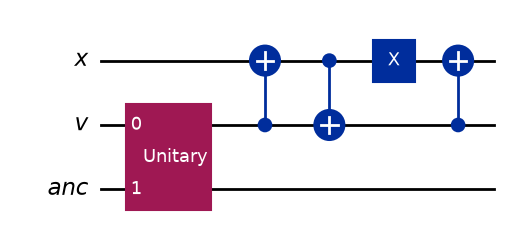

In [5]:
# Exemple lisible sur deux sites : position, vitesse et ancilla sont des registres distincts.
n_demo = 1
x = QuantumRegister(n_demo, "x")
v = QuantumRegister(1, "v")
anc = QuantumRegister(1, "anc")
circuit_demo = QuantumCircuit(x, v, anc)

omega_demo = omega_from_D(D_EFF, A_ADV)
collision_demo = collision_matrix(A_ADV, omega_demo)
unitary_demo, _ = dilation(collision_demo)
build_step(circuit_demo, n_demo, unitary_demo, shift="mcx")

display(circuit_demo.draw(output="mpl", fold=-1))


## 3. Simulation idéale avec Qiskit : encoder, post-sélectionner et décoder

Les fonctions précédentes construisent un `QuantumCircuit` Qiskit pour un pas complet. Cette section encode les populations dans l’état initial, simule le circuit avec `Statevector`, puis applique explicitement la post-sélection sur l’ancilla.

Le schéma ci-dessus montre un exemple sur deux sites. Les populations initiales sont stockées dans les amplitudes et l’ancilla commence à zéro. Après l’évolution unitaire, conserver `ancilla = 0` applique la collision effective ; la probabilité de succès est la norme au carré de la branche conservée.

La densité n’est pas directement une probabilité de mesure : elle est reconstruite en additionnant les amplitudes des deux directions et en suivant leur échelle physique. NumPy sert ici aux calculs matriciels et à la référence LBM classique ; toute évolution de circuit quantique est effectuée avec Qiskit.

In [ ]:
def encode_state(populations, n):
    """Encode les populations normalisées, avec l'ancilla initialisée à zéro."""
    n_sites = 2**n
    state = np.zeros(2 ** (n + 2), dtype=complex)
    state[:n_sites] = populations[0]
    state[n_sites : 2 * n_sites] = populations[1]
    return state / np.linalg.norm(state)


def postselect(state, n):
    """Garde ancilla=0, renormalise l'état et renvoie la probabilité de succès."""
    n_sites = 2**n
    retained_amplitudes = state[: 2 * n_sites]
    success_probability = float(np.vdot(retained_amplitudes, retained_amplitudes).real)

    postselected_state = np.zeros_like(state)
    postselected_state[: 2 * n_sites] = (
        retained_amplitudes / np.sqrt(success_probability)
    )
    return postselected_state, success_probability
 #On ferait mieux d'utiliser un post selcted de taille 2^(n+1)


def decode_density(state, n, physical_norm):
    """Reconstitue u(x)=f_+(x)+f_-(x) à l'échelle physique suivie."""
    n_sites = 2**n
    plus_amplitudes = state[:n_sites]
    minus_amplitudes = state[n_sites : 2 * n_sites]
    return physical_norm * np.real(plus_amplitudes + minus_amplitudes)


def run_ideal(n, a, omega, K, shift="mcx"):
    """Simule K pas idéaux et conserve les états et probabilités intermédiaires."""
    n_sites = 2**n
    collision = collision_matrix(a, omega)
    collision_unitary, alpha = dilation(collision)

    initial_density_values, _, _ = initial_density(n_sites)
    initial_populations = f_equilibrium(initial_density_values, a)
    physical_norm = np.linalg.norm(initial_populations)
    state = encode_state(initial_populations, n)

    results = {
        "psi": [state],
        "p": [],
        "u": [decode_density(state, n, physical_norm)],
        "norm": [physical_norm],
    }

    for _ in range(K):
        circuit = QuantumCircuit(n + 2)
        build_step(circuit, n, collision_unitary, shift=shift)
        evolved_state = Statevector(state).evolve(circuit).data
        state, success_probability = postselect(evolved_state, n)

        # Réintègre l'échelle perdue par la normalisation de l'état et par C/alpha.
        physical_norm *= np.sqrt(success_probability) * alpha
        results["psi"].append(state)
        results["p"].append(success_probability)
        results["norm"].append(physical_norm)
        results["u"].append(decode_density(state, n, physical_norm))

    return results

## 4. Vérification du circuit Qiskit contre la référence classique

La simulation quantique utilise `Statevector` de Qiskit et compare les densités reconstruites à la référence LBM NumPy. La référence NumPy reste utile comme solution classique indépendante ; elle ne sert pas à simuler les portes du circuit.

La comparaison teste les circuits d’incrémentation `mcx` et `draper`, ainsi que plusieurs tailles de réseau. L’erreur affichée est relative en norme \(\ell_2\). Les probabilités indiquées sont celles de réussir la post-sélection à chaque pas ; leur produit est la probabilité idéale de conserver toute la trajectoire.

### Que signifie `shift` ?

Le **transport** déplace chaque population d'un site vers son voisin. Avec le rebond aux parois, c'est un compteur : on ajoute 1 modulo $2N$ au registre $(x, v)$, vu comme un anneau de $2N$ états d'indice $k = x + N\,v$.

Cette opération unitaire peut se construire de deux façons, d'où l'argument `shift` :

- `shift="mcx"` : cascade de portes X multi-contrôlées. Le bit $j$ est inversé si tous les bits plus faibles valent 1, comme la retenue d'un compteur binaire.
- `shift="draper"` : additionneur de Draper. On passe en base de Fourier, où « $+1$ » devient de simples phases $e^{2i\pi k/2^m}$, puis on revient (QFT, phases, QFT$^{-1}$).

Les deux donnent **exactement la même opération**, donc les mêmes densités. Elles ne diffèrent que par le **nombre de portes** après compilation sur la chaîne de spins. `validate` vérifie qu'elles reproduisent toutes deux la référence NumPy ; la partie 8 compare leur coût.

In [7]:
def validate(n_list=(3, 4), shifts=("mcx", "draper")):
    """Compare les densités QLBM idéales aux trajectoires de référence NumPy."""
    omega = omega_from_D(D_EFF, A_ADV)
    tau = 1 / omega
    effective_diffusivity = D_from_omega(omega, A_ADV)
    print(
        f"omega = {omega:.4f}, tau = {tau:.4f}, "
        f"D_eff = {effective_diffusivity:.4f}"
    )

    for n in n_list:
        n_sites = 2**n
        reference = run_numpy(n_sites, A_ADV, omega, N_STEPS)

        for shift in shifts:
            quantum_result = run_ideal(
                n, A_ADV, omega, N_STEPS, shift=shift
            )
            relative_errors = []
            for step in range(N_STEPS + 1):
                reference_density = reference[step].sum(axis=0)
                quantum_density = quantum_result["u"][step]
                relative_errors.append(
                    np.linalg.norm(quantum_density - reference_density)
                    / np.linalg.norm(reference_density)
                )

            print(
                f"N={n_sites:2d} shift={shift:6s}  "
                f"erreur relative max = {max(relative_errors):.2e}  "
                f"p_par_pas = {np.round(quantum_result['p'], 4)}  "
                f"P_cumulee = {np.prod(quantum_result['p']):.4f}"
            )


validate()

omega = 1.6154, tau = 0.6190, D_eff = 0.1000
N= 8 shift=mcx     erreur relative max = 1.20e-15  p_par_pas = [0.6442 0.4917 0.681  0.5704]  P_cumulee = 0.1230
N= 8 shift=draper  erreur relative max = 2.92e-15  p_par_pas = [0.6442 0.4917 0.681  0.5704]  P_cumulee = 0.1230
N=16 shift=mcx     erreur relative max = 1.27e-14  p_par_pas = [0.6442 0.5906 0.66   0.6095]  P_cumulee = 0.1531
N=16 shift=draper  erreur relative max = 3.50e-15  p_par_pas = [0.6442 0.5906 0.66   0.6095]  P_cumulee = 0.1531


## 5. Coût probabiliste de la post-sélection

La collision est encodée dans une opération unitaire plus large, mais on ne conserve que la branche où l’ancilla vaut 0. Une exécution physique devra donc parfois recommencer la mesure jusqu’à obtenir cette branche (et tout reprendre).

Cette étude balaie plusieurs valeurs de diffusivité `D`. Pour chacune, elle calcule `omega` avec la relation du modèle, simule un pas puis plusieurs pas avec Qiskit `Statevector`, et enregistre les probabilités de succès. La probabilité cumulée est le produit des probabilités conditionnelles des pas successifs.

La figure quantifie le compromis : une simulation idéale peut être exacte conditionnellement au succès, tout en nécessitant de nombreuses répétitions pour obtenir une trajectoire complète.

In [8]:
def success_vs_D(n=3, Ds=None, a=A_ADV, K=N_STEPS):
    """Calcule les probabilités de succès pour une plage de diffusivités."""
    if Ds is None:
        Ds = np.linspace(0.02, 0.45, 12)

    first_step_probabilities = []
    cumulative_probabilities = []

    for diffusivity in Ds:
        omega = omega_from_D(diffusivity, a)
        result = run_ideal(n, a, omega, K)
        first_step_probabilities.append(result["p"][0])
        cumulative_probabilities.append(np.prod(result["p"]))

    return (
        Ds,
        np.array(first_step_probabilities),
        np.array(cumulative_probabilities),
    )

## 6. Compiler sur des qubits de spin avec SpinPulse

SpinPulse modélise une chaîne 1D de spins $\tfrac12$ avec l'Hamiltonien ($\hbar=1$) :

$$H(t)=\sum_i\Big[\tfrac{B_i(t)}{2}\big(\cos\varphi_i X_i+\sin\varphi_i Y_i\big)+\tfrac{\delta\omega_i(t)}{2}Z_i\Big]+\sum_i\tfrac{J_{i,i+1}(t)}{2}\big(X_iX_{i+1}+Y_iY_{i+1}+Z_iZ_{i+1}\big)$$

Chaque porte native correspond à **un** terme de $H$, commandé par un des paramètres du code. L'angle de rotation est l'aire de l'impulsion correspondante :

| Porte | Terme commandé | Angle | Durée minimale | Paramètre |
|---|---|---|---|---|
| `rx`, `ry` | champ de pilotage $B$ | $\theta=\int B\,dt$ | $\theta/B_{\max}$ (6,3 pour $\pi$) | `B_FIELD` = 0,5 |
| `rz` | décalage de fréquence $\delta\omega$ | $\theta=\int \delta\omega\,dt$ | $\theta/\delta_{\max}$ (15,7 pour $\pi$) | `DELTA` = 0,2 |
| `rzz` | échange $J$ | $\theta=\int J\,dt$ | $\theta/J_{\max}$ (157 pour $\pi/2$) | `J_COUP` = 0,01 |

Durées en pas d'échantillonnage ; ce sont des bornes inférieures.

**Condition de validité de `rzz`** : l'échange ne produit une interaction $ZZ$ pure que si l'écart de fréquence entre les deux spins, $\Delta=\delta\omega_i-\delta\omega_j$, domine : $J\ll\Delta$. Ici $J/\Delta=0{,}05$ si $\Delta$ atteint `DELTA`. La porte `rzz` est donc une séquence : on monte $\Delta$ (c'est la « rampe de $\Delta$ »), on applique l'impulsion de $J$, puis on redescend.

**Conséquence pour le coût** : `rzz` est environ 25 fois plus lente que `rx` ici. Le **nombre de `rzz`** compilées fixe la durée du circuit, donc son exposition au bruit. C'est pourquoi on compare `mcx` et `draper` sur la profondeur 2 qubits et le nombre de `rzz`.

Les autres paramètres : `Shape.GAUSSIAN` donne l'enveloppe des impulsions ; `optim=3` est le niveau d'optimisation du transpileur Qiskit (aucun sens physique) ; `RAMP` est la durée de montée des champs, et son effet pour des impulsions gaussiennes dépend de la version (vérifiez `inspect.signature(HardwareSpecs)`).

Le code de cette partie fait deux choses : `make_specs` fabrique la machine, `compile_step` compile un pas QLBM et en relève le temps de compilation, la profondeur, la profondeur 2 qubits et le nombre de `rzz`.

In [ ]:
import time

try:
    from spin_pulse.environment.experimental_environment import ExperimentalEnvironment
    from spin_pulse.environment.noise import NoiseType
    from spin_pulse.transpilation.hardware_specs import HardwareSpecs, Shape
    from spin_pulse.transpilation.pulse_circuit import PulseCircuit
    
    HAS_SPIN = True
except ImportError as error:
    HAS_SPIN = False
    print("SpinPulse indisponible :", error)

# Paramètres du modèle de qubits de spin (unités définies par SpinPulse).
B_FIELD = 0.5
DELTA = 0.2
J_COUP = 0.01
RAMP = 5


def make_hardware(n_qubits):
    """Crée les spécifications SpinPulse pour le nombre de qubits demandé."""
    return HardwareSpecs(
        n_qubits,
        B_FIELD,
        DELTA,
        J_COUP,
        Shape.GAUSSIAN,
        RAMP,
        optim=3,
    )


def compile_step(n, a, omega, shift="mcx", max_seconds=120):
    """Compile un pas et renvoie le circuit, les specs et des métriques.

    Renvoie None si la compilation dépasse le budget temporel demandé.
    """
    n_qubits = n + 2
    collision = collision_matrix(a, omega)
    collision_unitary, _ = dilation(collision)

    circuit = QuantumCircuit(n_qubits)
    build_step(
        circuit,
        n,
        collision_unitary,
        shift=shift,
        decompose_cx=True,
    )
    specs = make_hardware(n_qubits)

    start_time = time.time()
    isa_circuit = specs.gate_transpile(circuit)
    compilation_seconds = time.time() - start_time

    operation_counts = dict(isa_circuit.count_ops())
    metrics = {
        "N": 2**n,
        "qubits": n_qubits,
        "shift": shift,
        "t_compile": compilation_seconds,
        "depth": isa_circuit.depth(),
        "depth_2q": isa_circuit.depth(
            lambda instruction: instruction.operation.num_qubits == 2
        ),
        "n_rzz": operation_counts.get("rzz", 0),
        "ops": operation_counts,
    }

    if compilation_seconds > max_seconds:
        print(
            f"N={2**n} : compilation en {compilation_seconds:.0f}s "
            f"> {max_seconds}s ; arrêt de cette étude."
        )
        return None

    return isa_circuit, specs, metrics

## 7. Simulation bruitée : remettre les qubits dans le bon ordre

La compilation peut déplacer les qubits logiques vers des positions physiques différentes pour respecter la connectivité en chaîne. `isa.layout` contient ces correspondances ; les fonctions de cette section convertissent les états entre les ordres logique et physique.

La vérification de compilation compare deux simulations Qiskit `Statevector` : le circuit logique de référence et le circuit compilé idéal. Ensuite, `run_noisy` construit des impulsions SpinPulse, simule plusieurs réalisations du bruit et applique la post-sélection à chaque pas.

Pour chaque réalisation, le code suit la fidélité avec la trajectoire idéale, la probabilité de succès de la post-sélection et la densité reconstruite. Les fluctuations entre réalisations sont conservées pour afficher une moyenne et un écart-type.

In [10]:
def _layouts(isa, n_qubits):
    """Renvoie les permutations logique->physique initiale et finale."""
    layout = getattr(isa, "layout", None)
    if layout is None:
        identity = list(range(n_qubits))
        return identity, identity

    initial_layout = layout.initial_index_layout(filter_ancillas=True)
    final_layout = layout.final_index_layout(filter_ancillas=True)
    return initial_layout, final_layout


def embed(psi_logical, initial_layout, n_qubits):
    """Réordonne les axes d'un état logique selon le layout physique initial."""
    tensor_state = psi_logical.reshape((2,) * n_qubits)
    permutation = [0] * n_qubits

    for logical_qubit in range(n_qubits):
        logical_axis = n_qubits - 1 - logical_qubit
        physical_axis = n_qubits - 1 - initial_layout[logical_qubit]
        permutation[physical_axis] = logical_axis

    return np.transpose(tensor_state, permutation).reshape(-1)


def extract(psi_physical, final_layout, n_qubits):
    """Convertit un état physique en ordre logique après la compilation."""
    tensor_state = psi_physical.reshape((2,) * n_qubits)
    permutation = [0] * n_qubits

    for logical_qubit in range(n_qubits):
        logical_axis = n_qubits - 1 - logical_qubit
        physical_axis = n_qubits - 1 - final_layout[logical_qubit]
        permutation[logical_axis] = physical_axis

    return np.transpose(tensor_state, permutation).reshape(-1)


def apply_isa_ideal(isa, psi_logical, n_qubits):
    """Applique le circuit compilé idéal et remet le résultat en ordre logique."""
    initial_layout, final_layout = _layouts(isa, n_qubits)
    physical_state = Statevector(
        embed(psi_logical, initial_layout, n_qubits)
    ).evolve(isa).data
    return extract(physical_state, final_layout, n_qubits)


def check_compilation(isa, n, a, omega, shift):
    """Vérifie que compilation et routage préservent l'état idéal d'un pas."""
    n_qubits = n + 2
    collision = collision_matrix(a, omega)
    collision_unitary, _ = dilation(collision)

    density, _, _ = initial_density(2**n)
    initial_state = encode_state(f_equilibrium(density, a), n)

    reference_circuit = QuantumCircuit(n_qubits)
    build_step(reference_circuit, n, collision_unitary, shift=shift)
    reference_state = Statevector(initial_state).evolve(reference_circuit).data

    compiled_state = apply_isa_ideal(isa, initial_state, n_qubits)
    numerator = abs(np.vdot(reference_state, compiled_state)) ** 2
    denominator = (
        np.vdot(reference_state, reference_state).real
        * np.vdot(compiled_state, compiled_state).real
    )
    fidelity = numerator / denominator
    assert fidelity > 1 - 1e-6, (
        f"Compilation/layout incohérents (F={fidelity})"
    )
    return fidelity


def run_noisy(isa, specs, n, a, omega, K, n_real=8, T2S=500, noise=None):
    """Simule plusieurs trajectoires bruitées avec post-sélection à chaque pas."""
    n_qubits = n + 2
    noise_type = NoiseType.PINK if noise is None else noise
    initial_layout, final_layout = _layouts(isa, n_qubits)
    ideal = run_ideal(n, a, omega, K)
    alpha = dilation(collision_matrix(a, omega))[1]
    n_sites = 2**n

    fidelities = np.zeros((n_real, K))
    success_probabilities = np.zeros((n_real, K))
    densities = np.zeros((n_real, K + 1, n_sites))

    for realization in range(n_real):
        state = ideal["psi"][0]
        physical_norm = ideal["norm"][0]
        densities[realization, 0] = ideal["u"][0]

        for step in range(K):
            environment = ExperimentalEnvironment(
                hardware_specs=specs,
                noise_type=noise_type,
                T2S=T2S,
                duration=2**13,
                segment_duration=2**13,
            )
            pulse_circuit = PulseCircuit.from_circuit(
                isa, specs, exp_env=environment
            )
            noisy_circuit = pulse_circuit.to_circuit()

            physical_state = Statevector(
                embed(state, initial_layout, n_qubits)
            ).evolve(noisy_circuit).data
            logical_state = extract(
                physical_state, final_layout, n_qubits
            )
            state, success_probability = postselect(logical_state, n)
            physical_norm *= np.sqrt(success_probability) * alpha

            fidelities[realization, step] = abs(
                np.vdot(ideal["psi"][step + 1], state)
            ) ** 2
            success_probabilities[realization, step] = success_probability
            densities[realization, step + 1] = decode_density(
                state, n, physical_norm
            )

    return {
        "F": fidelities,
        "p": success_probabilities,
        "u": densities,
        "ideal": ideal,
    }


def gate_level_fidelity(isa, specs, n_real=5, T2S=500):
    """Renvoie la fidélité moyenne des portes selon l'API SpinPulse utilisée."""
    environment = ExperimentalEnvironment(
        hardware_specs=specs,
        noise_type=NoiseType.PINK,
        T2S=T2S,
        duration=2**13,
        segment_duration=2**13,
    )
    pulse_circuit = PulseCircuit.from_circuit(
        isa, specs, exp_env=environment
    )
    return pulse_circuit.mean_fidelity(environment)

## 8. Étude de compilation et de bruit pour plusieurs tailles

`study` compare les deux stratégies de transport et plusieurs tailles de réseau. Pour chaque cas, elle compile un pas, vérifie d’abord que le circuit compilé idéal est fidèle à la référence Qiskit, puis mesure les fidélités et lance les simulations bruitées.

Le garde-fou `max_seconds` arrête l’étude si la transpilation devient trop longue. Les métriques décrivent des aspects différents : profondeur et nombre de `RZZ` pour le coût du circuit, fidélité pour l’écart au circuit idéal et probabilité de post-sélection pour le coût probabiliste.

In [11]:
def study(ns=(3, 4), shifts=("mcx", "draper"), max_seconds=120, n_real=8):
    """Compile les circuits sélectionnés et mesure leur comportement bruité."""
    omega = omega_from_D(D_EFF, A_ADV)
    results = {}

    for n in ns:
        for shift in shifts:
            compilation = compile_step(
                n, A_ADV, omega, shift, max_seconds=max_seconds
            )
            if compilation is None:
                continue

            isa, specs, metrics = compilation
            metrics["F_check"] = check_compilation(
                isa, n, A_ADV, omega, shift
            )
            metrics["F_gate"] = (
                gate_level_fidelity(isa, specs) if n + 2 <= 7 else None
            )

            noisy_result = run_noisy(
                isa,
                specs,
                n,
                A_ADV,
                omega,
                N_STEPS,
                n_real=n_real,
            )
            metrics["F_state_mean"] = noisy_result["F"].mean(axis=0)
            metrics["p_noisy_mean"] = noisy_result["p"].mean(axis=0)
            results[(n, shift)] = (metrics, noisy_result)

            printable_metrics = {
                key: value for key, value in metrics.items() if key != "ops"
            }
            print(printable_metrics)

    return results

## 9. Comparer les densités et visualiser les résultats

La première figure superpose la référence LBM NumPy, le QLBM idéal simulé avec Qiskit `Statevector` et la solution gaussienne de l’équation continue. Si une étude SpinPulse a été exécutée, elle ajoute la moyenne des densités bruitées et leur écart-type entre réalisations.

La seconde figure trace les probabilités de post-sélection pour un pas et pour toute la séquence, en fonction de la diffusivité. Les figures sont enregistrées dans le répertoire courant.

**Interprétation :** le QLBM idéal doit suivre la référence NumPy ; la solution analytique infinie peut différer près des parois réfléchissantes. Les barres d’erreur SpinPulse représentent la variabilité du bruit simulé.

ValueError: Environment duration 8192 trace too shortfor circuit duration 18434 at t_lab time 0

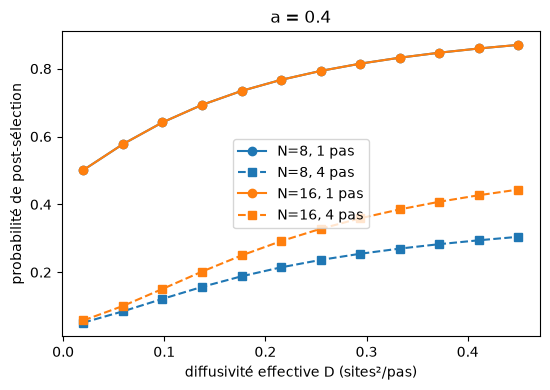

In [16]:
def plot_comparison(
    n_list=(3, 4), shift="mcx", noisy_results=None,
    fname="qlbm_comparaison.png",
):
    """Trace les densités de référence, idéales, analytiques et éventuellement bruitées."""
    omega = omega_from_D(D_EFF, A_ADV)
    diffusivity = D_from_omega(omega, A_ADV)
    figure, axes = plt.subplots(
        1,
        len(n_list),
        figsize=(6.2 * len(n_list), 4.4),
        squeeze=False,
    )

    for axis, n in zip(axes[0], n_list):
        n_sites = 2**n
        reference = run_numpy(n_sites, A_ADV, omega, N_STEPS)
        quantum = run_ideal(n, A_ADV, omega, N_STEPS, shift=shift)
        _, center, width = initial_density(n_sites)
        positions = np.arange(n_sites)

        axis.plot(
            positions,
            reference[0].sum(axis=0),
            ":",
            color="gray",
            label="t = 0",
        )
        axis.plot(
            positions,
            reference[-1].sum(axis=0),
            "-",
            color="C0",
            linewidth=2,
            label=f"NumPy LBM (t = {N_STEPS})",
        )
        axis.plot(
            positions,
            quantum["u"][-1],
            "o",
            color="C3",
            markerfacecolor="none",
            markersize=9,
            label="QLBM idéal (post-sélection)",
        )

        analytical_x, analytical_density = analytic_gaussian(
            n_sites, A_ADV, diffusivity, N_STEPS, center, width
        )
        axis.plot(
            analytical_x,
            analytical_density,
            "--",
            color="black",
            linewidth=1,
            label="analytique (domaine infini)",
        )

        if noisy_results and (n, shift) in noisy_results:
            noisy_densities = noisy_results[(n, shift)][1]["u"][:, -1, :]
            axis.errorbar(
                positions,
                noisy_densities.mean(axis=0),
                noisy_densities.std(axis=0),
                fmt="s",
                color="C2",
                markersize=5,
                capsize=3,
                label="QLBM bruité (SpinPulse)",
            )

        relative_error = (
            np.linalg.norm(quantum["u"][-1] - reference[-1].sum(axis=0))
            / np.linalg.norm(reference[-1].sum(axis=0))
        )
        axis.set_title(
            f"N = {n_sites} sites ({n + 2} qubits)  |  "
            f"erreur QLBM/NumPy = {relative_error:.1e}\n"
            f"P_succès cumulée = {np.prod(quantum['p']):.3f}"
        )
        axis.set_xlabel("site x")
        axis.set_ylabel("u(x)")
        axis.legend(fontsize=8)

    figure.tight_layout()
    return figure


def plot_success(fname="qlbm_postselection.png"):
    """Trace les succès de post-sélection par pas et pour toute la trajectoire."""
    figure, axis = plt.subplots(figsize=(5.6, 4))

    for n, color in [(3, "C0"), (4, "C1")]:
        diffusivities, first_step, cumulative = success_vs_D(n)
        axis.plot(
            diffusivities,
            first_step,
            "-o",
            color=color,
            label=f"N={2**n}, 1 pas",
        )
        axis.plot(
            diffusivities,
            cumulative,
            "--s",
            color=color,
            label=f"N={2**n}, {N_STEPS} pas",
        )

    axis.set_xlabel("diffusivité effective D (sites²/pas)")
    axis.set_ylabel("probabilité de post-sélection")
    axis.legend()
    axis.set_title(f"a = {A_ADV}")
    figure.tight_layout()
    return figure


if __name__ == "__main__":
    plot_success()
    noisy = study() if HAS_SPIN else None
    plot_comparison(noisy_results=noisy)
    plt.show()